In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
import joblib
import json


from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_auc_score, classification_report, confusion_matrix, roc_curve, precision_recall_curve, precision_score, recall_score, f1_score
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from xgboost import XGBClassifier

In [3]:
BASE_DIR = Path.cwd().parent

DATA_DIR = BASE_DIR / "data"
MODELS_DIR = BASE_DIR / "models"

DATA_DIR.mkdir(parents=True, exist_ok=True)
MODELS_DIR.mkdir(parents=True, exist_ok=True)

In [4]:
X_train = pd.read_csv(DATA_DIR / "X_train_final.csv")
y_train = pd.read_csv(DATA_DIR / "y_train_raw.csv")
X_test = pd.read_csv(DATA_DIR / "X_test_final.csv")
y_test = pd.read_csv(DATA_DIR / "y_test_raw.csv")

In [5]:
scaler = StandardScaler()
X_tr_scaled = scaler.fit_transform(X_train)
X_te_scaled = scaler.transform(X_test)

In [6]:
y_train_1d = y_train.values.ravel()
y_test_1d = y_test.values.ravel()

In [7]:
lr_model = LogisticRegression(max_iter=1000, random_state=42, class_weight='balanced')
lr_model.fit(X_tr_scaled, y_train_1d)
lr_proba = lr_model.predict_proba(X_te_scaled)[:,1]

lr_auc = roc_auc_score(y_test_1d, lr_proba)
print(f"Logistic Regression ROC-AUC: {lr_auc:.4f}")

Logistic Regression ROC-AUC: 0.8190


In [8]:
rf_model = RandomForestClassifier(random_state=42, n_estimators=100, n_jobs=-1)
rf_model.fit(X_tr_scaled, y_train_1d)
rf_proba = rf_model.predict_proba(X_te_scaled)[:,1]

rf_auc = roc_auc_score(y_test_1d, rf_proba)
print(f"Random Forest ROC-AUC: {rf_auc:.4f}")

Random Forest ROC-AUC: 0.8421


In [9]:
scale_weight = len(y_train_1d[y_train_1d == 0]) / len(y_train_1d[y_train_1d == 1])
xgb_model = XGBClassifier(n_estimators=100, random_state=42, learning_rate=0.1, n_jobs=-1, scale_pos_weight=scale_weight)
xgb_model.fit(X_tr_scaled, y_train_1d)
xgb_proba = xgb_model.predict_proba(X_te_scaled)[:,1]

xgb_auc = roc_auc_score(y_test_1d, xgb_proba)
print(f"XGBoost ROC-AUC: {xgb_auc:.4f}")

XGBoost ROC-AUC: 0.8615


Model                    Val AUC    Val F1   Threshold
______________________________________________________
Logistic Regression       0.8112    0.4023       0.717
Random Forest             0.8312    0.4144       0.310
XGBoost                   0.8479    0.4100       0.772

Best model (Validation): Random Forest | Threshold = 0.310


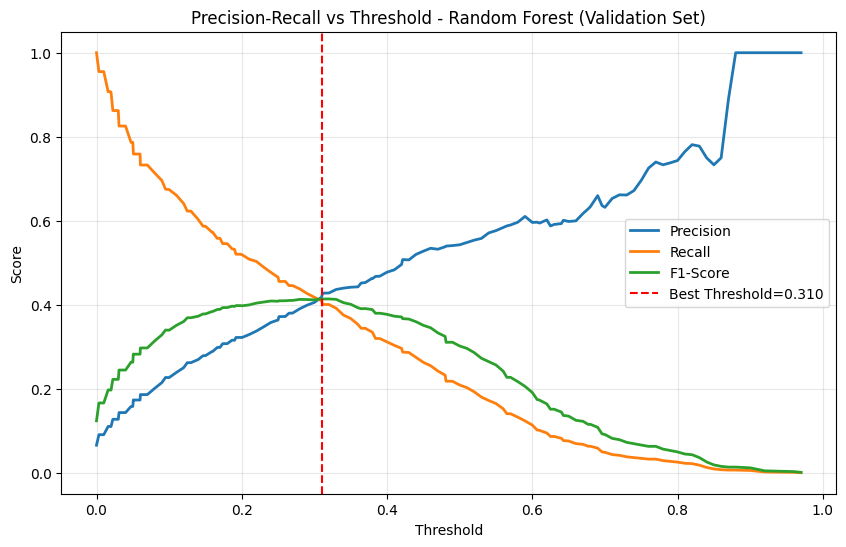

In [10]:
X_fit, X_val, y_fit, y_val = train_test_split(
    X_train, y_train_1d, test_size=0.2, stratify=y_train_1d, random_state=42
)

val_scaler = StandardScaler()
X_fit_scaled = val_scaler.fit_transform(X_fit)
X_val_scaled = val_scaler.transform(X_val)

scale_weight_fit = len(y_fit[y_fit == 0]) / len(y_fit[y_fit == 1])

candidates = {
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=42, class_weight='balanced'),
    "Random Forest": RandomForestClassifier(random_state=42, n_estimators=100, n_jobs=-1),
    "XGBoost": XGBClassifier(n_estimators=100, random_state=42, learning_rate=0.1, n_jobs=-1, scale_pos_weight=scale_weight_fit),
}

val_results = {}
for name, model in candidates.items():
    model.fit(X_fit_scaled, y_fit)
    val_proba = model.predict_proba(X_val_scaled)[:,1]

    precisions, recalls, thresholds = precision_recall_curve(y_val, val_proba)
    f1_scores = 2 * (precisions * recalls) / (precisions + recalls + 1e-8)
    best_idx = np.argmax(f1_scores[:-1])

    val_results[name] = {
        "threshold": thresholds[best_idx],
        "val_f1": f1_scores[best_idx],
        "val_auc": roc_auc_score(y_val, val_proba),
        "precisions": precisions, "recalls": recalls, "f1_scores": f1_scores, "thresholds": thresholds,
    }

print(f"{'Model':<22}{'Val AUC':>10}{'Val F1':>10}{'Threshold':>12}")
print("_"*54)
for name, r in val_results.items():
    print(f"{name:<22}{r['val_auc']:>10.4f}{r['val_f1']:>10.4f}{r['threshold']:>12.3f}")

best_name = max(val_results, key=lambda n: val_results[n]["val_f1"])
best_threshold = val_results[best_name]["threshold"]
print(f"\nBest model (Validation): {best_name} | Threshold = {best_threshold:.3f}")

r = val_results[best_name]
plt.figure(figsize=(10, 6))
plt.plot(r["thresholds"], r["precisions"][:-1], label='Precision', linewidth=2)
plt.plot(r["thresholds"], r["recalls"][:-1], label='Recall', linewidth=2)
plt.plot(r["thresholds"], r["f1_scores"][:-1], label='F1-Score', linewidth=2)
plt.axvline(x=best_threshold, color='r', linestyle='--', label=f'Best Threshold={best_threshold:.3f}')
plt.xlabel('Threshold')
plt.ylabel('Score')
plt.title(f'Precision-Recall vs Threshold - {best_name} (Validation Set)')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

In [11]:
final_models = {
    "Logistic Regression": (lr_model, lr_proba),
    "Random Forest": (rf_model, rf_proba),
    "XGBoost": (xgb_model, xgb_proba),
}

print(f"{'Model':<22}{'Test AUC':>10}{'Threshold':>12}{'Prec(1)':>10}{'Recall(1)':>11}{'F1(1)':>8}")
print("_"*73)
for name, (m, proba) in final_models.items():
    t = val_results[name]["threshold"]
    pred = (proba >= t).astype(int)
    print(f"{name:<22}{roc_auc_score(y_test_1d, proba):>10.4f}{t:>12.3f}"
          f"{precision_score(y_test_1d, pred):>10.3f}{recall_score(y_test_1d, pred):>11.3f}{f1_score(y_test_1d, pred):>8.3f}")

best_model, best_proba = final_models[best_name]
threshold = best_threshold
best_pred = (best_proba >= threshold).astype(int)
best_auc = roc_auc_score(y_test_1d, best_proba)

print(f"\nSelected model: {best_name} (selected on Validation)")
print(f"Threshold used: {threshold:.3f}")
print(f"ROC-AUC: {best_auc:.4f}")
print("_"*40)
print(classification_report(y_test_1d, best_pred))

Model                   Test AUC   Threshold   Prec(1)  Recall(1)   F1(1)
_________________________________________________________________________
Logistic Regression       0.8190       0.717     0.390      0.433   0.410
Random Forest             0.8421       0.310     0.421      0.391   0.405
XGBoost                   0.8615       0.772     0.398      0.468   0.430

Selected model: Random Forest (selected on Validation)
Threshold used: 0.310
ROC-AUC: 0.8421
________________________________________
              precision    recall  f1-score   support

           0       0.96      0.96      0.96     19571
           1       0.42      0.39      0.41      1390

    accuracy                           0.92     20961
   macro avg       0.69      0.68      0.68     20961
weighted avg       0.92      0.92      0.92     20961



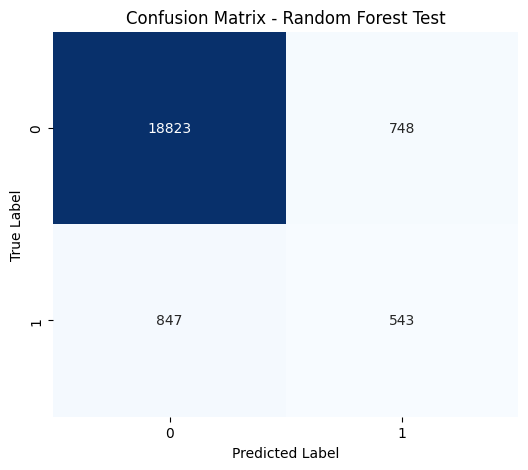

In [12]:
cm = confusion_matrix(y_test_1d, best_pred)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False)
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.title(f'Confusion Matrix - {best_name} Test')
plt.show()

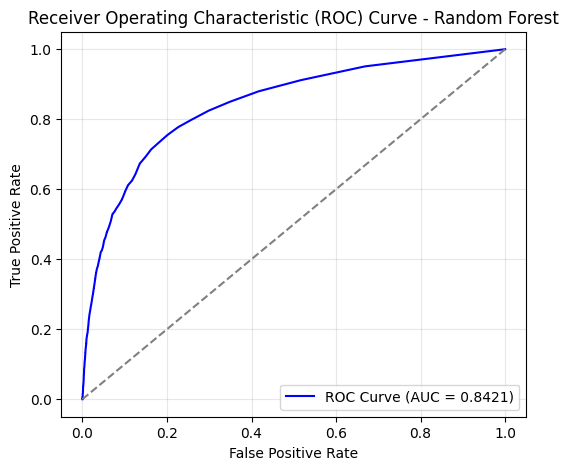

In [13]:
fpr, tpr, _ = roc_curve(y_test_1d, best_proba)
plt.figure(figsize=(6, 5))
plt.plot(fpr, tpr, color='blue', label=f'ROC Curve (AUC = {best_auc:.4f})')
plt.plot([0, 1], [0, 1], color='gray', linestyle='--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title(f'Receiver Operating Characteristic (ROC) Curve - {best_name}')
plt.legend(loc='lower right')
plt.grid(True, alpha=0.3)
plt.show()

In [14]:
joblib.dump(xgb_model, MODELS_DIR / "xgb_credit_model.pkl")
joblib.dump(best_model, MODELS_DIR / "best_credit_model.pkl")
joblib.dump(scaler, MODELS_DIR / "scaler.pkl")

['d:\\My_First_ML_Model\\models\\scaler.pkl']

In [15]:
with open(MODELS_DIR / "threshold.json", "w") as f:
    json.dump({"model": best_name, "threshold": float(best_threshold)}, f)